In [ ]:
# Реализуйте высокочастотную фильтрацию на основе ядра Гаусса
# Реализуйте вычисление свертки с помощью преобразования Фурье
# Реализуйте удаление периодического шума с помощью преобразования Фурье

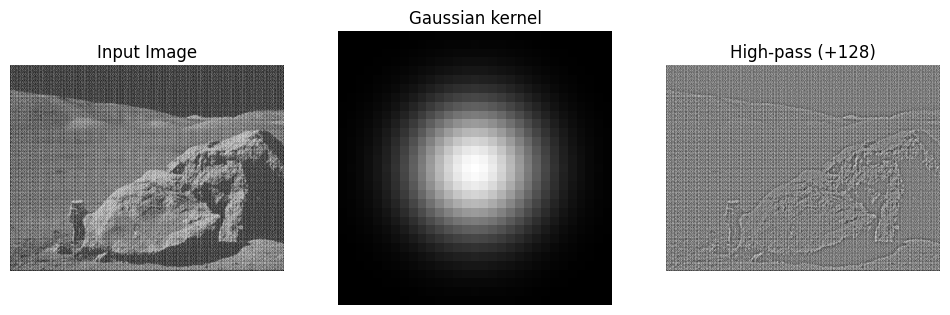

In [21]:
#Задание 1


import numpy as np
import cv2  as cv
import matplotlib.pyplot as plt
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
assert img is not None

ksize = 31
sigma = 5.0
gauss_1d = cv.getGaussianKernel(ksize, sigma)
gauss_kernel = np.outer(gauss_1d, gauss_1d).astype(np.float32)

low_pass = cv.filter2D(np.float32(img), -1, gauss_kernel)

high_pass = np.float32(img) - low_pass

high_pass_show = np.clip(high_pass + 128, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Input Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(gauss_kernel, cmap='gray')
plt.title('Gaussian kernel')
plt.axis('off')

plt.subplot(133)
plt.imshow(high_pass_show, cmap='gray')
plt.title('High-pass (+128)')
plt.axis('off')

plt.show()

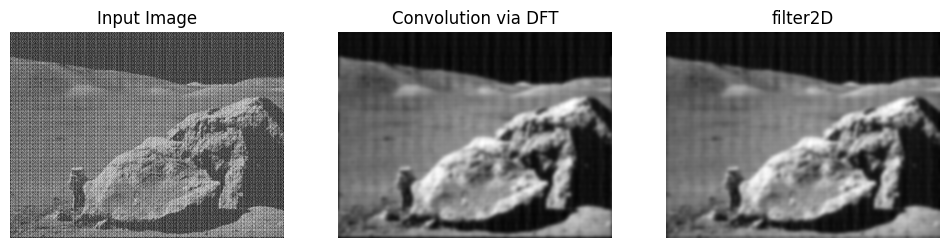

In [22]:
#Задание 2

def dft_convolve(image, kernel):

    image_f = np.float32(image)
    h, w = image_f.shape
    kh, kw = kernel.shape


    kernel_pad = np.zeros((h, w), np.float32)
    y0 = h // 2 - kh // 2
    x0 = w // 2 - kw // 2
    kernel_pad[y0:y0 + kh, x0:x0 + kw] = kernel

    kernel_pad = np.fft.ifftshift(kernel_pad)

    dft_img = cv.dft(image_f, flags=cv.DFT_COMPLEX_OUTPUT)
    dft_kernel = cv.dft(kernel_pad, flags=cv.DFT_COMPLEX_OUTPUT)

    dft_product = cv.mulSpectrums(dft_img, dft_kernel, 0)

    conv = cv.idft(dft_product)
    conv = cv.magnitude(conv[:, :, 0], conv[:, :, 1])

    return conv

conv_fft = dft_convolve(img, gauss_kernel)

conv_cv = cv.filter2D(np.float32(img), -1, gauss_kernel)

conv_fft_show = cv.normalize(conv_fft, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)
conv_cv_show = cv.normalize(conv_cv, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(12, 4))

plt.subplot(131)
plt.imshow(img, cmap='gray')
plt.title('Input Image')
plt.axis('off')

plt.subplot(132)
plt.imshow(conv_fft_show, cmap='gray')
plt.title('Convolution via DFT')
plt.axis('off')

plt.subplot(133)
plt.imshow(conv_cv_show, cmap='gray')
plt.title('filter2D')
plt.axis('off')

plt.show()

detected peaks: 341
-> kept top 40 strongest
removed 1143 spectrum px (0.245%)
idft stats: min=-88.69, max=274.50, mean=107.65, std=41.09


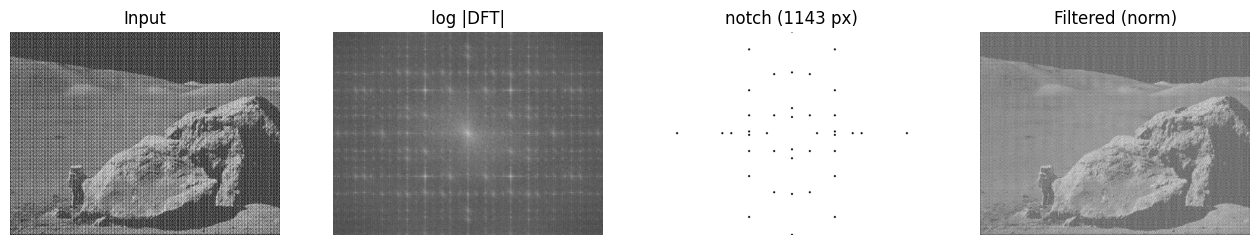

In [23]:
# Задание 3

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude = cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1])
log_mag = np.log(magnitude + 1)

h, w = img.shape
cy, cx = h // 2, w // 2
Y, X = np.ogrid[:h, :w]
dist = np.sqrt((Y - cy) ** 2 + (X - cx) ** 2)
outside = dist > 20

kernel5 = np.ones((5, 5), np.float32)
local_max  = cv.dilate(log_mag, kernel5)
is_locmax  = (log_mag >= local_max - 1e-6) & outside

local_mean = cv.blur(log_mag, (15, 15))
contrast   = log_mag - local_mean
peak_mask  = is_locmax & (contrast > 2.5)

n = int(peak_mask.sum())
print(f"detected peaks: {n}")

MAX_PEAKS = 40
if n > MAX_PEAKS:
    flat = np.where(peak_mask, log_mag, -np.inf).ravel()
    top  = np.argpartition(flat, -MAX_PEAKS)[-MAX_PEAKS:]
    peak_mask = np.zeros((h, w), bool)
    peak_mask.ravel()[top] = True
    n = MAX_PEAKS
    print(f"-> kept top {MAX_PEAKS} strongest")
elif n < 2:
    print("WARNING: too few peaks; increase contrast threshold (2.5 -> 1.5)")

notch_r = 3
kernel_notch = np.zeros((2 * notch_r + 1,) * 2, np.uint8)
cv.circle(kernel_notch, (notch_r, notch_r), notch_r, 1, -1)

peak_u8 = (peak_mask.astype(np.uint8) * 255)
peak_u8 = cv.dilate(peak_u8, kernel_notch)
mask = np.ones((h, w, 2), np.float32)
mask[peak_u8 > 0] = 0

removed = int((mask[:, :, 0] == 0).sum())
print(f"removed {removed} spectrum px ({100 * removed / (h * w):.3f}%)")

filtered_dft_shift = dft_shift * mask
f_ishift = np.ascontiguousarray(np.fft.ifftshift(filtered_dft_shift))
img_back = cv.idft(f_ishift, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

print(f"idft stats: min={img_back.min():.2f}, max={img_back.max():.2f}, "
      f"mean={img_back.mean():.2f}, std={img_back.std():.2f}")

img_back_u8 = cv.normalize(img_back, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(16, 4))
plt.subplot(141); plt.imshow(img, cmap='gray');                       plt.title('Input');           plt.axis('off')
plt.subplot(142); plt.imshow(log_mag, cmap='gray');                   plt.title('log |DFT|');       plt.axis('off')
plt.subplot(143); plt.imshow(mask[:, :, 0], cmap='gray');             plt.title(f'notch ({removed} px)'); plt.axis('off')
plt.subplot(144); plt.imshow(img_back_u8, cmap='gray');               plt.title('Filtered (norm)'); plt.axis('off')
plt.show()